# Problem 1: Camera Extrinsics from a Checkerboard

All of your code goes in `P1_extrinsics.py`. This notebook only runs and plots it.

In [12]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt

from P1_extrinsics import checkerboard_points, project_points, compute_homography, pose_from_homography, reprojection_rmse

os.makedirs("plots", exist_ok=True)



K = np.array([[471.14628085, -4.94771211, 295.13159043],
              [0., 436.71106326, 240.96582594],
              [0., 0., 1.]])
SQUARE_SIZE = 0.0205  # m
NX, NY = 9, 7         # inner corners along x and y

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Corner Detection
`cv2.findChessboardCorners` finds the inner corners of the board in pixel coordinates. If OpenCV does not install on your machine, the same corners are provided in `data/corners.npz`.

(63, 2)


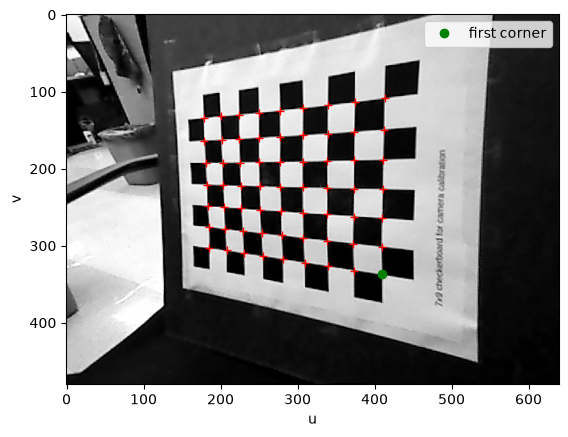

In [11]:
image = plt.imread("data/checkerboard.png")
try:
    import cv2
    ret = cv2.findChessboardCorners(cv2.imread("data/checkerboard.png", 0), (NX, NY))
    found: bool = ret[0]
    corners: cv2.typing.MatLike = ret[1]
    uv = corners.squeeze().astype(float) if found else np.load("data/corners.npz")["uv"]
except ImportError:
    uv = np.load("data/corners.npz")["uv"]
print(uv.shape)

fig, ax = plt.subplots()
ax.imshow(image, cmap="gray")
ax.plot(uv[:, 0], uv[:, 1], "r+")
ax.plot(uv[0, 0], uv[0, 1], "go", label="first corner")
ax.set_xlabel("u")
ax.set_ylabel("v")
ax.legend()
plt.show()

## Sanity Checks
Run this cell after implementing the functions. It only checks simple synthetic cases; passing it does not guarantee full credit.

In [ ]:
W = checkerboard_points(3, 2, 0.1)
assert W.shape == (6, 2)
assert np.allclose(W, [[0, 0], [0.1, 0], [0.2, 0], [0, 0.1], [0.1, 0.1], [0.2, 0.1]])

# Synthetic camera 0.5 m in front of the board
R_true = np.array([[1., 0, 0], [0, -1, 0], [0, 0, -1]])
t_true = np.array([0.05, -0.02, 0.5])
W = checkerboard_points(NX, NY, SQUARE_SIZE)
X = np.column_stack([W, np.zeros(len(W))])
uv_syn = project_points(K, R_true, t_true, X)
assert uv_syn.shape == (len(W), 2)

H = compute_homography(W, uv_syn)
assert H.shape == (3, 3) and np.isclose(H[2, 2], 1.0)
R, t = pose_from_homography(K, -3.0 * H)  # the scale and sign of H are arbitrary
assert np.allclose(R, R_true, atol=1e-6) and np.allclose(t, t_true, atol=1e-6)
assert np.isclose(reprojection_rmse(uv_syn, project_points(K, R, t, X)), 0.0, atol=1e-6)
print("Sanity checks passed")

[[ 0.1   -0.04 ]
 [ 0.141 -0.04 ]
 [ 0.182 -0.04 ]
 [ 0.223 -0.04 ]
 [ 0.264 -0.04 ]
 [ 0.305 -0.04 ]
 [ 0.346 -0.04 ]
 [ 0.387 -0.04 ]
 [ 0.428 -0.04 ]
 [ 0.1   -0.081]
 [ 0.141 -0.081]
 [ 0.182 -0.081]
 [ 0.223 -0.081]
 [ 0.264 -0.081]
 [ 0.305 -0.081]
 [ 0.346 -0.081]
 [ 0.387 -0.081]
 [ 0.428 -0.081]
 [ 0.1   -0.122]
 [ 0.141 -0.122]
 [ 0.182 -0.122]
 [ 0.223 -0.122]
 [ 0.264 -0.122]
 [ 0.305 -0.122]
 [ 0.346 -0.122]
 [ 0.387 -0.122]
 [ 0.428 -0.122]
 [ 0.1   -0.163]
 [ 0.141 -0.163]
 [ 0.182 -0.163]
 [ 0.223 -0.163]
 [ 0.264 -0.163]
 [ 0.305 -0.163]
 [ 0.346 -0.163]
 [ 0.387 -0.163]
 [ 0.428 -0.163]
 [ 0.1   -0.204]
 [ 0.141 -0.204]
 [ 0.182 -0.204]
 [ 0.223 -0.204]
 [ 0.264 -0.204]
 [ 0.305 -0.204]
 [ 0.346 -0.204]
 [ 0.387 -0.204]
 [ 0.428 -0.204]
 [ 0.1   -0.245]
 [ 0.141 -0.245]
 [ 0.182 -0.245]
 [ 0.223 -0.245]
 [ 0.264 -0.245]
 [ 0.305 -0.245]
 [ 0.346 -0.245]
 [ 0.387 -0.245]
 [ 0.428 -0.245]
 [ 0.1   -0.286]
 [ 0.141 -0.286]
 [ 0.182 -0.286]
 [ 0.223 -0.286]
 [ 0.264 -0.28

SyntaxError: 'break' outside loop (1680996489.py, line 13)

## Extrinsic Calibration

In [ ]:
W = checkerboard_points(NX, NY, SQUARE_SIZE)
X = np.column_stack([W, np.zeros(len(W))])

H = compute_homography(W, uv)
R, t = pose_from_homography(K, H)
np.set_printoptions(precision=4, suppress=True)
print("R =\n", R)
print("t =", t)
print("distance from camera to board origin: %.4f m" % np.linalg.norm(t))

# Columns of K^-1 H after normalizing by the first column, before any correction
A = np.linalg.solve(K, H)
A = A / np.linalg.norm(A[:, 0])
print("||r1|| = %.4f, r0 . r1 = %.4f" % (np.linalg.norm(A[:, 1]), A[:, 0] @ A[:, 1]))

uv_proj = project_points(K, R, t, X)
print("reprojection RMSE: %.3f px" % reprojection_rmse(uv, uv_proj))

## World to Camera Projection
Project the board corners and a secret point cloud (defined in the board frame) into the image.

In [ ]:
secret = np.load("data/secret.npy")
uv_secret = project_points(K, R, t, secret)

fig, ax = plt.subplots()
ax.imshow(image, cmap="gray")
ax.plot(uv[:, 0], uv[:, 1], "r+", label="detected")
ax.plot(uv_proj[:, 0], uv_proj[:, 1], "bx", label="reprojected")
ax.scatter(uv_secret[:, 0], uv_secret[:, 1], s=0.5, c="c")
ax.set_xlabel("u")
ax.set_ylabel("v")
ax.legend()
plt.savefig("plots/p1_reprojection.png", bbox_inches="tight")
plt.show()

## Errors in the Intrinsics
Recompute the pose with the focal lengths scaled by 0.95 and 1.05. Use this for part (iv).

In [ ]:
def rotation_angle_deg(Ra, Rb):
    return np.degrees(np.arccos(np.clip((np.trace(Ra.T @ Rb) - 1) / 2, -1, 1)))

print(" scale |              t              | t / t_nominal       | rot. change | RMSE")
for s in [0.95, 1.0, 1.05]:
    K_s = K.copy()
    K_s[0, 0] *= s
    K_s[1, 1] *= s
    R_s, t_s = pose_from_homography(K_s, H)
    rmse = reprojection_rmse(uv, project_points(K_s, R_s, t_s, X))
    print(f" {s:4.2f}  | {np.array2string(t_s, precision=4)} | {np.array2string(t_s / t, precision=3)} | {rotation_angle_deg(R_s, R):6.2f} deg  | {rmse:.2f} px")